# Rainfall Prediction for Melbourne
### An end-to-end machine learning pipeline to predict same-day rain from historical weather data

**Stack:** Python · pandas · scikit-learn (Pipeline, ColumnTransformer, GridSearchCV) · matplotlib · seaborn

---

## 1. Project overview

**Goal.** Predict whether it will rain on a given day in the Melbourne area (`Yes` / `No`) using weather observations recorded up to and including the previous day. A model like this supports everyday decisions such as whether to cycle to work or schedule outdoor activities.

**What this project demonstrates**

- Cleaning a real-world weather dataset and reasoning about **data leakage** when defining the prediction target
- **Feature engineering** (deriving a `Season` feature from dates) and narrowing data granularity to a coherent region
- Leak-free **preprocessing + modelling pipelines** (scaling, one-hot encoding) that are re-fit inside every cross-validation fold
- **Hyperparameter tuning** with stratified k-fold `GridSearchCV`
- Honest **evaluation on imbalanced classes** (precision / recall / F1, confusion matrices) instead of relying on accuracy alone
- **Model comparison**: Random Forest vs. Logistic Regression
- **Interpretability** through feature importances

**Contents**

1. Project overview
2. Dataset
3. Setup and data loading
4. Data cleaning and leakage considerations
5. Feature engineering and exploratory analysis
6. Train / test split and preprocessing
7. Model 1: Random Forest
8. Feature importances
9. Model 2: Logistic Regression and comparison
10. Conclusions, limitations and next steps

## 2. Dataset

Daily weather observations from the Australian Government's [Bureau of Meteorology](http://www.bom.gov.au/climate/dwo/), covering 2008–2017 across many Australian weather stations. The data was compiled on Kaggle as the [Rain in Australia / weather-dataset-rattle-package](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) dataset (`weatherAUS.csv`). Column definitions follow the [BoM daily weather observations glossary](http://www.bom.gov.au/climate/dwo/IDCJDW0000.shtml).

| Field | Description | Unit | Type |
| :-- | :-- | :-- | :-- |
| Date | Date of the observation (YYYY-MM-DD) | Date | object |
| Location | Location of the observation | Location | object |
| MinTemp | Minimum temperature | °C | float |
| MaxTemp | Maximum temperature | °C | float |
| Rainfall | Amount of rainfall | mm | float |
| Evaporation | Amount of evaporation | mm | float |
| Sunshine | Amount of bright sunshine | hours | float |
| WindGustDir | Direction of the strongest gust | Compass point | object |
| WindGustSpeed | Speed of the strongest gust | km/h | float |
| WindDir9am | Wind direction averaged over the 10 minutes before 9am | Compass point | object |
| WindDir3pm | Wind direction averaged over the 10 minutes before 3pm | Compass point | object |
| WindSpeed9am | Wind speed averaged over the 10 minutes before 9am | km/h | float |
| WindSpeed3pm | Wind speed averaged over the 10 minutes before 3pm | km/h | float |
| Humidity9am | Humidity at 9am | % | float |
| Humidity3pm | Humidity at 3pm | % | float |
| Pressure9am | Atmospheric pressure reduced to mean sea level at 9am | hPa | float |
| Pressure3pm | Atmospheric pressure reduced to mean sea level at 3pm | hPa | float |
| Cloud9am | Fraction of sky obscured by cloud at 9am | oktas (eighths) | float |
| Cloud3pm | Fraction of sky obscured by cloud at 3pm | oktas (eighths) | float |
| Temp9am | Temperature at 9am | °C | float |
| Temp3pm | Temperature at 3pm | °C | float |
| RainToday | At least 1 mm of rain on the day | Yes / No | object |
| RainTomorrow | At least 1 mm of rain on the next day | Yes / No | object |

## 3. Setup and data loading

The dataset is read from `data/weatherAUS.csv`. If the file is not present, it is downloaded automatically (see also `download_data.py` and the README). Install dependencies with `pip install -r requirements.txt`.

In [1]:
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
# scikit-learn >= 1.8 deprecates LogisticRegression(penalty=...); silence that noise
warnings.filterwarnings("ignore", message=".*penalty.*")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
DATA_URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
            "_0eYOqji3unP1tDNKWZMjg/weatherAUS-2.csv")
DATA_PATH = Path("data/weatherAUS.csv")


def load_data(path: Path = DATA_PATH, url: str = DATA_URL) -> pd.DataFrame:
    """Load the weather dataset, downloading it on first use."""
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f"Downloading dataset to {path} ...")
        urlretrieve(url, path)
    return pd.read_csv(path)


df_raw = load_data()
print(f"Raw data: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Raw data: 145,460 rows x 23 columns


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 4. Data cleaning and leakage considerations

### 4.1 Missing values

Share of missing values per column:

In [3]:
(df_raw.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("missing_%")

,missing_%
Sunshine,48.0
Evaporation,43.2
Cloud3pm,40.8
Cloud9am,38.4
Pressure9am,10.4
Pressure3pm,10.3
WindDir9am,7.3
WindGustSpeed,7.1
WindGustDir,7.1
Humidity3pm,3.1


`Sunshine`, `Evaporation` and the cloud-cover columns are missing for a large share of rows, too many to impute sensibly. To keep the first version of the model simple and transparent, rows with any missing value are dropped. The result is still large enough (tens of thousands of observations nationally) that imputation is not required.

In [4]:
df = df_raw.dropna()
print(f"Rows kept after dropping missing values: {len(df):,} of {len(df_raw):,}")
df.info()

Rows kept after dropping missing values: 56,420 of 145,460
<class 'pandas.DataFrame'>
Index: 56420 entries, 6049 to 142302
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           56420 non-null  str    
 1   Location       56420 non-null  str    
 2   MinTemp        56420 non-null  float64
 3   MaxTemp        56420 non-null  float64
 4   Rainfall       56420 non-null  float64
 5   Evaporation    56420 non-null  float64
 6   Sunshine       56420 non-null  float64
 7   WindGustDir    56420 non-null  str    
 8   WindGustSpeed  56420 non-null  float64
 9   WindDir9am     56420 non-null  str    
 10  WindDir3pm     56420 non-null  str    
 11  WindSpeed9am   56420 non-null  float64
 12  WindSpeed3pm   56420 non-null  float64
 13  Humidity9am    56420 non-null  float64
 14  Humidity3pm    56420 non-null  float64
 15  Pressure9am    56420 non-null  float64
 16  Pressure3pm    56420 non-null  float64
 17  Clo

### 4.2 Defining the target without leaking information

The dataset's original target, `RainTomorrow`, asks for a *next-day* forecast. Several columns (`Rainfall`, `Sunshine`, `Evaporation`, `MaxTemp`, `MinTemp`, `Temp3pm`, `WindGustSpeed`, `RainToday`, and similar) summarise the **entire day**, so they are only fully known once that day is over. Using them to predict tomorrow would be unrealistic for a live forecasting system, and they would not be available at prediction time.

**Reframing the problem:** instead, predict **whether it rains today, using weather data up to and including yesterday**. Every available feature is then legitimately known when the prediction is made. To avoid confusion, the columns are renamed accordingly:

| Original | Renamed | Meaning |
| :-- | :-- | :-- |
| `RainToday` | `RainYesterday` | Rain on the previous day (feature) |
| `RainTomorrow` | `RainToday` | Rain on the day being predicted (**target**) |

In [5]:
df = df.rename(columns={"RainToday": "RainYesterday",
                        "RainTomorrow": "RainToday"})

### 4.3 Data granularity: focus on one region

Rain patterns differ strongly between Australian climate zones, so a single model over all stations would need to be far more complex. Watsonia (about 15 km) and Melbourne Airport (about 18 km) are both close to central Melbourne, so these three stations are grouped into one localised dataset. `Location` is kept as a categorical feature to capture remaining local variation.

In [6]:
MELBOURNE_AREA = ["Melbourne", "MelbourneAirport", "Watsonia"]
df = df[df["Location"].isin(MELBOURNE_AREA)]
df.info()

<class 'pandas.DataFrame'>
Index: 7557 entries, 64191 to 80997
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           7557 non-null   str    
 1   Location       7557 non-null   str    
 2   MinTemp        7557 non-null   float64
 3   MaxTemp        7557 non-null   float64
 4   Rainfall       7557 non-null   float64
 5   Evaporation    7557 non-null   float64
 6   Sunshine       7557 non-null   float64
 7   WindGustDir    7557 non-null   str    
 8   WindGustSpeed  7557 non-null   float64
 9   WindDir9am     7557 non-null   str    
 10  WindDir3pm     7557 non-null   str    
 11  WindSpeed9am   7557 non-null   float64
 12  WindSpeed3pm   7557 non-null   float64
 13  Humidity9am    7557 non-null   float64
 14  Humidity3pm    7557 non-null   float64
 15  Pressure9am    7557 non-null   float64
 16  Pressure3pm    7557 non-null   float64
 17  Cloud9am       7557 non-null   float64
 18  Cloud3pm       7557

This leaves a few thousand records, which is enough for a reasonably good model. More data could be added later by including similar climate zones or refreshing the data from the source.

## 5. Feature engineering and exploratory analysis

### 5.1 Seasonality

Rainfall in Melbourne is seasonal, so a `Season` feature is derived from the date. `Date` is dropped afterwards because the season carries most of the useful signal. A function maps months to (southern-hemisphere) seasons.

In [7]:
def date_to_season(date):
    """Map a timestamp to its southern-hemisphere season."""
    month = date.month
    if month in (12, 1, 2):
        return "Summer"
    elif month in (3, 4, 5):
        return "Autumn"
    elif month in (6, 7, 8):
        return "Winter"
    else:
        return "Spring"

In [8]:
# Convert 'Date' to datetime and derive the season
df["Date"] = pd.to_datetime(df["Date"])
df["Season"] = df["Date"].apply(date_to_season)

# Drop the raw date column
df = df.drop(columns="Date")
df.head()

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainYesterday,RainToday,Season
64191,MelbourneAirport,11.2,19.9,0.0,5.6,8.8,SW,69.0,W,SW,33.0,43.0,55.0,37.0,1005.1,1006.4,7.0,7.0,15.9,18.1,No,Yes,Summer
64192,MelbourneAirport,7.8,17.8,1.2,7.2,12.9,SSE,56.0,SW,SSE,31.0,26.0,50.0,43.0,1018.0,1019.3,6.0,7.0,12.5,15.8,Yes,No,Summer
64193,MelbourneAirport,6.3,21.1,0.0,6.2,10.5,SSE,31.0,E,S,13.0,19.0,51.0,35.0,1020.8,1017.6,1.0,7.0,13.4,19.6,No,No,Summer
64194,MelbourneAirport,8.1,29.2,0.0,6.4,12.5,SSE,35.0,NE,SSE,2.0,20.0,67.0,23.0,1016.2,1012.8,5.0,4.0,16.0,28.2,No,No,Summer
64195,MelbourneAirport,9.7,29.0,0.0,7.4,12.3,SE,33.0,SW,SSE,9.0,20.0,51.0,31.0,1011.9,1010.3,6.0,2.0,19.4,27.1,No,No,Summer


### 5.2 Target balance

Before modelling, check how balanced the target is.

In [9]:
X = df.drop(columns="RainToday")
y = df["RainToday"]

class_counts = y.value_counts()
class_share = y.value_counts(normalize=True)
pd.DataFrame({"count": class_counts, "share": class_share})

,count,share
RainToday,,
No,5766,0.763001
Yes,1791,0.236999


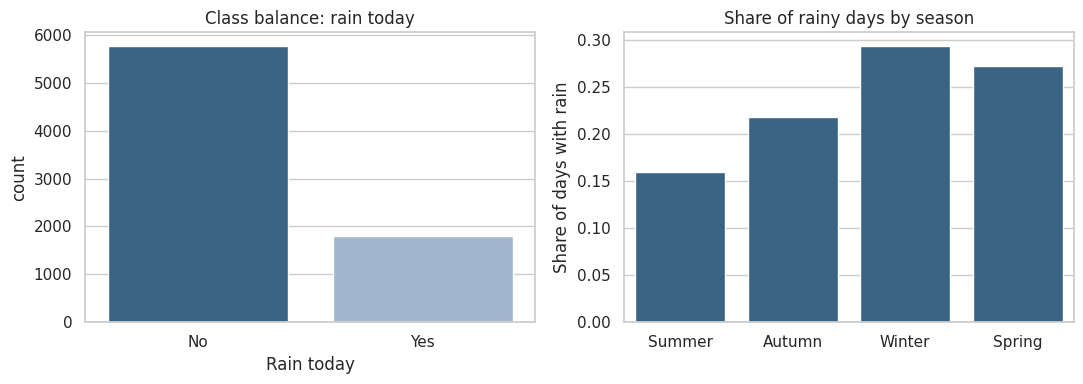

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x=y, order=["No", "Yes"], ax=axes[0], palette=["#9bb7d4", "#2f6690"], hue=y, legend=False)
axes[0].set_title("Class balance: rain today")
axes[0].set_xlabel("Rain today")

season_order = ["Summer", "Autumn", "Winter", "Spring"]
rain_rate = (df.assign(rain=(df["RainToday"] == "Yes"))
               .groupby("Season")["rain"].mean().reindex(season_order))
sns.barplot(x=rain_rate.index, y=rain_rate.values, ax=axes[1], color="#2f6690")
axes[1].set_title("Share of rainy days by season")
axes[1].set_ylabel("Share of days with rain")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

### 5.3 What the class balance tells us

The next cell quantifies how often it rains and how well a trivial "it never rains" classifier would score.

In [11]:
rain_rate_overall = (y == "Yes").mean()
baseline_accuracy = (y == "No").mean()

print(f"Share of days with rain:                 {rain_rate_overall:.1%}")
print(f"Approx. rainy days per year:             {rain_rate_overall * 365:.0f}")
print(f"Accuracy of 'always predict no rain':    {baseline_accuracy:.1%}")

Share of days with rain:                 23.7%
Approx. rainy days per year:             87
Accuracy of 'always predict no rain':    76.3%


**Observations**

- It rains on a minority of days, so the dataset is **imbalanced** (not extremely, but enough to matter).
- A naive classifier that always predicts "no rain" already achieves an accuracy equal to the majority-class share printed above. **Accuracy alone is therefore a misleading metric**: the model must be judged against that baseline and on class-specific metrics, especially recall on the rain class (how many rainy days are actually caught).
- Next steps: use **stratified** splitting and cross-validation so every fold keeps the same class ratio, and report precision, recall and F1 per class.

## 6. Train / test split and preprocessing

The data is split 80 / 20 with stratification on the target. All preprocessing is placed inside a scikit-learn `Pipeline`, so scaling and encoding are learned **only from training folds**, which prevents leakage from the validation or test data.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")

Train: (6045, 22)   Test: (1512, 22)


Numeric and categorical columns are detected automatically and handled by separate transformers: standard scaling for numeric features and one-hot encoding for categorical ones (unseen categories are ignored at prediction time).

In [13]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numeric features:    ", numeric_features)
print("Categorical features:", categorical_features)

Numeric features:     ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Categorical features: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainYesterday', 'Season']


In [14]:
numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

## 7. Model 1: Random Forest

The preprocessing step and a `RandomForestClassifier` are combined into a single pipeline. A grid search with stratified 5-fold cross-validation then tunes the forest's size, depth and split threshold. In every fold the pipeline is fit on the training portion and scored on the held-out portion.

In [15]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=RANDOM_STATE)),
])

rf_param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [16]:
rf_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=cv,
                         scoring="accuracy", n_jobs=-1, verbose=1)
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [None, 10, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computatio

In [17]:
print("Best parameters:", rf_search.best_params_)
print(f"Best cross-validation accuracy: {rf_search.best_score_:.4f}")

rf_test_accuracy = rf_search.score(X_test, y_test)
print(f"Test accuracy:                  {rf_test_accuracy:.4f}")

Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best cross-validation accuracy: 0.8524
Test accuracy:                  0.8446


### 7.1 Evaluation on unseen data

Accuracy gives a first impression, but with imbalanced classes the per-class metrics and the confusion matrix are more informative.

In [18]:
y_pred_rf = rf_search.predict(X_test)

print("Classification report (Random Forest):\n")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Classification report (Random Forest):

              precision    recall  f1-score   support

          No       0.86      0.95      0.90      1154
         Yes       0.75      0.51      0.61       358

    accuracy                           0.84      1512
   macro avg       0.81      0.73      0.76      1512
weighted avg       0.84      0.84      0.83      1512



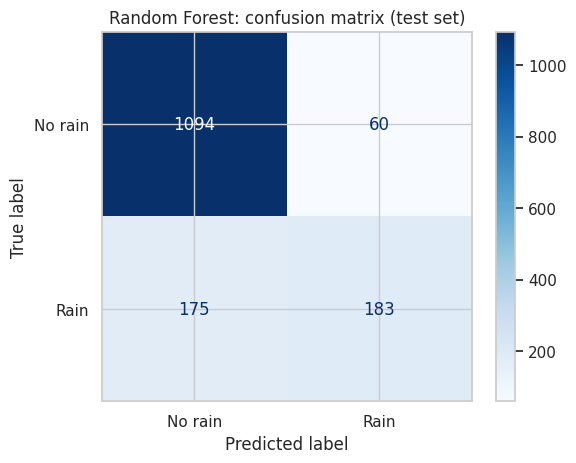

In [19]:
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"])
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_rf, display_labels=["No rain", "Rain"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest: confusion matrix (test set)")
plt.show()

The **true positive rate** (recall for the rain class) is the fraction of rainy days the model correctly flags: `TP / (TP + FN)`.

In [20]:
tn, fp, fn, tp = conf_matrix_rf.ravel()
rf_tpr = tp / (tp + fn)
rf_precision = tp / (tp + fp)

print(f"True positives: {tp}   False negatives: {fn}   False positives: {fp}   True negatives: {tn}")
print(f"True positive rate (recall, rain): {rf_tpr:.4f}")
print(f"Precision (rain):                  {rf_precision:.4f}")

True positives: 183   False negatives: 175   False positives: 60   True negatives: 1094
True positive rate (recall, rain): 0.5112
Precision (rain):                  0.7531


## 8. Feature importances

To interpret the forest, importances are mapped back through the pipeline. One-hot encoded columns are named after the categorical feature and category they came from, while numeric columns keep their original names.

In [21]:
best_rf = rf_search.best_estimator_
feature_importances = best_rf["classifier"].feature_importances_

feature_names = numeric_features + list(
    best_rf["preprocessor"].named_transformers_["cat"]
         .named_steps["onehot"].get_feature_names_out(categorical_features)
)

importance_df = (pd.DataFrame({"Feature": feature_names, "Importance": feature_importances})
                   .sort_values(by="Importance", ascending=False))
importance_df.head(10)

,Feature,Importance
9,Humidity3pm,0.120752
11,Pressure3pm,0.090827
10,Pressure9am,0.085730
4,Sunshine,0.081560
5,WindGustSpeed,0.050779
15,Temp3pm,0.045733
1,MaxTemp,0.041407
0,MinTemp,0.040418
14,Temp9am,0.039146
8,Humidity9am,0.036119


Most important feature: Humidity3pm


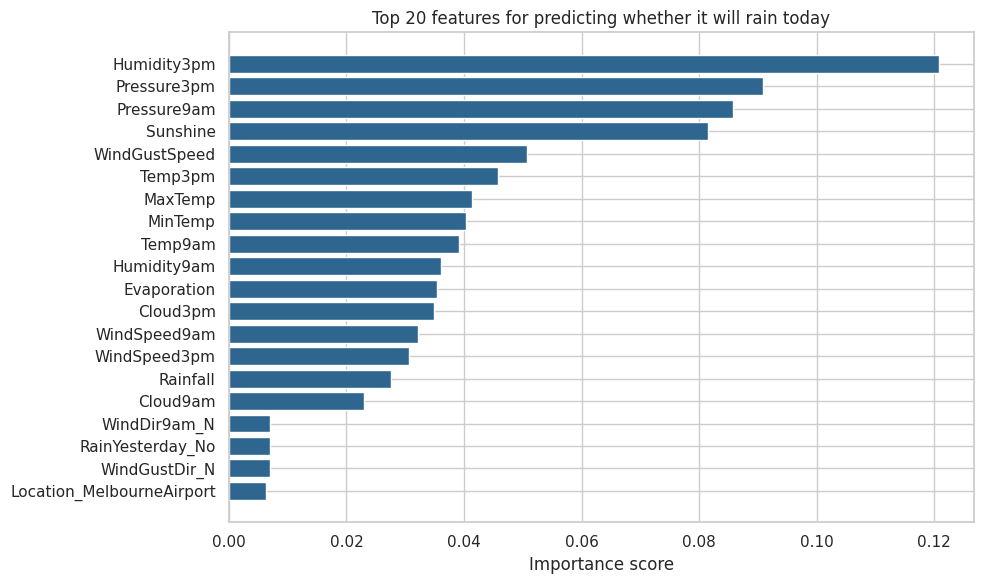

In [22]:
N = 20  # number of features to display
top_features = importance_df.head(N)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"], color="#2f6690")
plt.gca().invert_yaxis()  # most important feature on top
plt.title(f"Top {N} features for predicting whether it will rain today")
plt.xlabel("Importance score")
plt.tight_layout()
plt.show()

print("Most important feature:", importance_df.iloc[0]["Feature"])

## 9. Model 2: Logistic Regression and comparison

To check whether a simpler, more interpretable model can compete, the classifier in the pipeline is swapped for `LogisticRegression`. The same preprocessing, cross-validation strategy and test set are reused so the comparison is like-for-like. The search covers the regularisation type (`l1` / `l2`) and class weighting (`None` / `balanced`), where `balanced` increases the penalty for missing rainy days.

In [23]:
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
])

lr_param_grid = {
    "classifier__solver": ["liblinear"],
    "classifier__penalty": ["l1", "l2"],
    "classifier__class_weight": [None, "balanced"],
}

lr_search = GridSearchCV(lr_pipeline, lr_param_grid, cv=cv,
                         scoring="accuracy", n_jobs=-1, verbose=1)
lr_search.fit(X_train, y_train)

print("Best parameters:", lr_search.best_params_)
print(f"Best cross-validation accuracy: {lr_search.best_score_:.4f}")
print(f"Test accuracy:                  {lr_search.score(X_test, y_test):.4f}")

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'classifier__class_weight': None, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Best cross-validation accuracy: 0.8372
Test accuracy:                  0.8300


In [24]:
y_pred_lr = lr_search.predict(X_test)

print("Classification report (Logistic Regression):\n")
print(classification_report(y_test, y_pred_lr, zero_division=0))

conf_matrix_lr = confusion_matrix(y_test, y_pred_lr, labels=["No", "Yes"])

Classification report (Logistic Regression):

              precision    recall  f1-score   support

          No       0.86      0.93      0.89      1154
         Yes       0.69      0.51      0.59       358

    accuracy                           0.83      1512
   macro avg       0.77      0.72      0.74      1512
weighted avg       0.82      0.83      0.82      1512



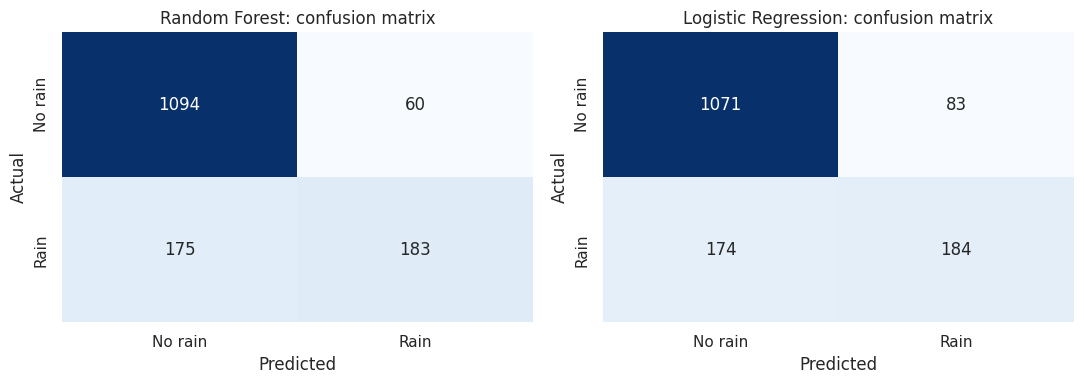

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cm, title in zip(axes,
                         [conf_matrix_rf, conf_matrix_lr],
                         ["Random Forest", "Logistic Regression"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No rain", "Rain"], yticklabels=["No rain", "Rain"])
    ax.set_title(f"{title}: confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### 9.1 Side-by-side comparison

In [26]:
def summarise(name, y_true, y_hat):
    """Collect headline test-set metrics for the rain class."""
    report = classification_report(y_true, y_hat, output_dict=True, zero_division=0)
    return {
        "Model": name,
        "Accuracy": report["accuracy"],
        "Precision (rain)": report["Yes"]["precision"],
        "Recall / TPR (rain)": report["Yes"]["recall"],
        "F1 (rain)": report["Yes"]["f1-score"],
    }


comparison = pd.DataFrame([
    summarise("Random Forest", y_test, y_pred_rf),
    summarise("Logistic Regression", y_test, y_pred_lr),
]).set_index("Model")

comparison.style.format("{:.4f}")

,Accuracy,Precision (rain),Recall / TPR (rain),F1 (rain)
Model,,,,
Random Forest,0.8446,0.7531,0.5112,0.6090
Logistic Regression,0.8300,0.6891,0.5140,0.5888


## 10. Conclusions, limitations and next steps

### Results at a glance

| Model | Test accuracy | Precision (rain) | Recall (rain) | F1 (rain) |
| :-- | --: | --: | --: | --: |
| Baseline: "always no rain" | 0.7630 | n/a | 0.0000 | n/a |
| Random Forest (tuned) | **0.8446** | **0.7531** | 0.5112 | **0.6090** |
| Logistic Regression (tuned) | 0.8300 | 0.6891 | 0.5140 | 0.5888 |

*Test set: 1,512 days (20% stratified hold-out of 7,557 Melbourne-area observations). Rain falls on 23.7% of days (about 87 days per year).*

### Key takeaways

- **Framing matters.** Reframing the task as "will it rain *today*, given data up to yesterday" removed same-day leakage and produced a realistic prediction problem.
- **Both models clearly beat the naive baseline.** The tuned Random Forest reaches 84.5% test accuracy (85.2% cross-validated), about 8 percentage points above the 76.3% you would get by always predicting "no rain". Logistic Regression reaches 83.0%.
- **Accuracy hides the real weakness.** Both models catch only about half of the rainy days (recall 0.511 for the Random Forest: 183 of 358 rainy days detected, 175 missed; 0.514 for Logistic Regression). Missing rain is the dominant error type.
- **Random Forest is the better all-round model.** At practically the same recall, it raises fewer false alarms (60 vs. 83 false positives), giving higher precision (0.753 vs. 0.689) and F1 (0.609 vs. 0.589). It is the preferred model here, though the linear model is a competitive and far more interpretable baseline.
- **The physics is sensible.** The most important features are afternoon humidity (`Humidity3pm`, 0.121), followed by atmospheric pressure at 3pm and 9am, sunshine hours and wind gust speed. Seasonality is visible in the raw data (rain on about 29% of winter days vs. 16% of summer days), but the individual `Season` dummies did not rank among the top 20 features, so humidity, pressure and sunshine appear to carry most of that signal.
- **Class weighting did not help under accuracy scoring.** The grid search selected `class_weight=None` for Logistic Regression because models were selected on accuracy, which favours the majority class.

### Limitations

- Rows with missing values were dropped rather than imputed, which may bias the sample towards stations and days with complete instrumentation.
- Observations on neighbouring days are correlated, so a random stratified split can be slightly optimistic compared with a strictly chronological split.
- Only three nearby stations are modelled; results may not transfer to other climate zones.
- The grids are deliberately small, and model selection used accuracy as the scoring metric.

### Next steps

- Evaluate with a **time-based train/test split** (e.g. train on earlier years, test on the latest year).
- Optimise for **recall or F1** on the rain class, tune the **decision threshold**, and calibrate predicted probabilities.
- Impute missing values (e.g. `SimpleImputer` / `IterativeImputer`) to recover the dropped rows, including `Sunshine` and `Cloud*` features.
- Add lag features (rolling rainfall, pressure change over previous days) and try gradient-boosted models such as `HistGradientBoostingClassifier`.
- Expand the data to more stations or a larger region with a location-aware model.

### Save the trained model (optional)

The fitted pipeline includes all preprocessing, so it can be loaded later and applied directly to raw feature data.

In [27]:
Path("models").mkdir(exist_ok=True)
joblib.dump(rf_search.best_estimator_, "models/rain_random_forest_pipeline.joblib")
print("Saved models/rain_random_forest_pipeline.joblib")

Saved models/rain_random_forest_pipeline.joblib
